# Агент-художник: анализ экспериментов

Художники-агенты уточняют детали картины у арт-эксперта, пишут промпты для генераторов и
переделывают работу по его критике. Здесь — разбор четырёх экспериментов:

1. **Общий контекст** — помогает ли художникам видеть вопросы друг друга (`shared`) или нет (`isolated`).
2. **Культурная асимметрия** — один генератор (Yandex ART) с русским и английским промптом на культурных и нейтральных идеях.
3. **«Нейро-Крокодил»** — поговорки только изображением; как английский промпт их переводит.
4. **«Испорченный телефон»** — картина → пересказ → картина по пересказу → …

Художники: **A** — SDXL-Turbo, промпт на английском; **B** — Yandex ART, на русском; **C** — Yandex ART, на английском.

Ноутбук только читает готовые прогоны из `runs/` и кеши анализа — моделей не вызывает, перезапуск бесплатный.
Недостающее считается командами `agent-artist-experiment recover / translation / telephone` (см. README).

In [1]:
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

from agent_artist import analysis
from agent_artist.summary import summarize

RUNS = Path("runs")
pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def show(path, max_width=1400):
    """Показать картинку, уменьшенную до max_width и сжатую в JPEG, чтобы ноутбук оставался лёгким."""
    if not Path(path).exists():
        print(f"Нет файла {path} — эксперимент ещё не запускался")
        return
    picture = PILImage.open(path).convert("RGB")
    picture.thumbnail((max_width, max_width * 4))
    buffer = BytesIO()
    picture.save(buffer, format="JPEG", quality=82)
    display(Image(data=buffer.getvalue(), format="jpeg"))

## Что есть в данных

In [2]:
scores = analysis.scores_frame([RUNS])
experiments = scores.assign(experiment=scores.run.str.split("/").str[1])
(experiments.groupby("experiment")
 .agg(прогонов=("run", "nunique"), картин=("score", "size"), отказов=("refused", "sum"),
      идей=("idea", "nunique"))
 .sort_values("картин", ascending=False))

,прогонов,картин,отказов,идей
experiment,,,,
culture,12,72,14,6
proverbs,12,72,2,6
keep_best,12,48,0,2
experienced,8,32,8,2
experiment_lighthouse,4,24,0,1
clients,5,20,1,1
20261013_221703,1,16,0,1
20261013_203512,1,4,0,1
20261013_204957,1,2,0,1


## 1. Общий контекст: shared против isolated

Одна идея («Маяк в шторм»), по несколько повторов в каждом режиме, три итерации без ранней остановки.
Оценки — от эксперта, который видит картину. Ниже — средняя оценка по итерациям.

  ! Пропускаю runs/experiment_lighthouse/03_isolated/log.json: нет оценок или старый формат лога
  ! Пропускаю runs/experiment_lighthouse/03_shared/log.json: нет оценок или старый формат лога


## Маяк в шторм — эксперт видит картинку

| Художник | Режим | Прогонов | Первая | Последняя | Лучшая | Прирост |
|---|---|---|---|---|---|---|
| A (local, анг) | isolated | 2 | 4.5 ± 2.1 | 4.0 ± 0.0 | 5.0 ± 1.4 | -0.5 ± 2.1 |
| A (local, анг) | shared | 2 | 4.0 ± 0.0 | 5.5 ± 0.7 | 5.5 ± 0.7 | 1.5 ± 0.7 |
| B (yandex_art, рус) | isolated | 2 | 6.5 ± 0.7 | 6.0 ± 2.8 | 7.5 ± 0.7 | -0.5 ± 3.5 |
| B (yandex_art, рус) | shared | 2 | 7.0 ± 1.4 | 7.0 ± 0.0 | 8.0 ± 0.0 | 0.0 ± 1.4 |

Средняя оценка по итерациям:

| Художник | Режим | 1 | 2 | 3 |
|---|---|---|---|---|
| A (local, анг) | isolated | 4.5 ± 2.1 | 3.5 ± 0.7 | 4.0 ± 0.0 |
| A (local, анг) | shared | 4.0 ± 0.0 | 3.5 ± 0.7 | 5.5 ± 0.7 |
| B (yandex_art, рус) | isolated | 6.5 ± 0.7 | 6.0 ± 0.0 | 6.0 ± 2.8 |
| B (yandex_art, рус) | shared | 7.0 ± 1.4 | 7.0 ± 1.4 | 7.0 ± 0.0 |


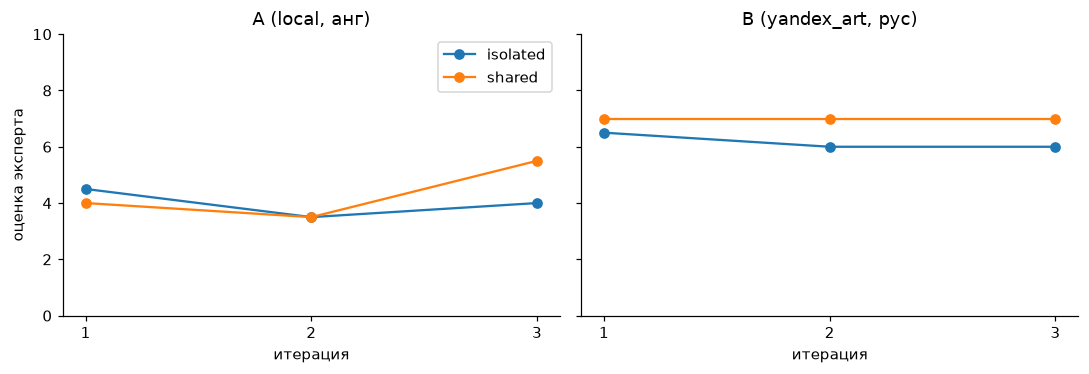

In [3]:
LIGHTHOUSE = RUNS / "experiment_lighthouse"
display(Markdown(summarize([LIGHTHOUSE])))

lighthouse = scores[scores.run.str.startswith(str(LIGHTHOUSE))]
if not lighthouse.empty:
    fig, axes = plt.subplots(1, lighthouse.artist.nunique(), figsize=(10, 3.5), sharey=True)
    for ax, (artist, group) in zip(axes, lighthouse.groupby("artist")):
        for mode, by_mode in group.groupby("mode"):
            means = by_mode.groupby("iteration").score.mean()
            ax.plot(means.index, means.values, marker="o", label=mode)
        ax.set(title=artist, xlabel="итерация", ylim=(0, 10), xticks=sorted(group.iteration.unique()))
    axes[0].set_ylabel("оценка эксперта")
    axes[0].legend()
    plt.tight_layout()

Та же серия глазами **слепого зрителя** («угадай заказ»): он видит только картину и не знает заказа.
`details_conveyed` — доля согласованных с экспертом пунктов, которые действительно видны на картине.

In [4]:
recovery = analysis.recovery_frame([RUNS])
lighthouse_recovery = recovery[recovery.run.str.startswith(str(LIGHTHOUSE))]
if lighthouse_recovery.empty:
    print("Нет recovery.json — запустите: agent-artist-experiment recover runs/experiment_lighthouse")
else:
    display(lighthouse_recovery.pivot_table(index="artist", columns="mode", values="details_conveyed",
                                            aggfunc="mean").style.format("{:.0%}"))

mode,isolated,shared
artist,,
"A (local, анг)",32%,47%
"B (yandex_art, рус)",59%,68%


## 2. Культурная асимметрия

Четыре культурные идеи и две нейтральные, художники A, B, C. Сравнение **B и C** — один генератор,
разные языки промпта: чистый эффект языка. Гипотеза: на культурных идеях разрыв B − C больше, чем на нейтральных.

Отказы модерации Yandex ART (оценка 0) считаются отдельно — это не качество картины, а то, что её не нарисовали.

In [5]:
CULTURE = RUNS / "culture"
CULTURAL_IDEAS = ["Масленица на деревенской площади", "Баба-Яга у избушки на курьих ножках",
                  "Двор хрущёвки зимним вечером", "Мороз и солнце; день чудесный"]
culture = scores[scores.run.str.startswith(str(CULTURE))].copy()
culture["kind"] = culture.idea.map(lambda idea: "культурная" if idea in CULTURAL_IDEAS else "нейтральная")

if culture.empty:
    print("Серия ещё не запускалась: bash experiments/culture_language.sh")
else:
    print("Отказы генератора (картин без изображения):")
    display(culture.pivot_table(index="idea", columns="artist", values="refused", aggfunc="sum"))
    drawn = culture[~culture.refused]
    print("Средняя оценка нарисованных картин:")
    display(drawn.pivot_table(index=["kind", "idea"], columns="artist", values="score",
                              aggfunc="mean").round(1))

Отказы генератора (картин без изображения):


artist,"A (local, анг)","B (yandex_art, рус)","C (yandex_art, анг)"
idea,,,
Баба-Яга у избушки на курьих ножках,0,1,2
Двор хрущёвки зимним вечером,0,2,2
Лиса в зимнем лесу,0,2,0
Масленица на деревенской площади,0,2,2
Маяк в шторм,0,0,1
Мороз и солнце; день чудесный,0,0,0


Средняя оценка нарисованных картин:


artist                                           A (local, анг)  \
kind        idea                                                  
культурная  Баба-Яга у избушки на курьих ножках             2.8   
            Двор хрущёвки зимним вечером                    2.8   
            Масленица на деревенской площади                2.8   
            Мороз и солнце; день чудесный                   5.0   
нейтральная Лиса в зимнем лесу                              3.2   
            Маяк в шторм                                    4.0   

artist                                           B (yandex_art, рус)  \
kind        idea                                                       
культурная  Баба-Яга у избушки на курьих ножках                  4.7   
            Двор хрущёвки зимним вечером                         4.0   
            Масленица на деревенской площади                     5.0   
            Мороз и солнце; день чудесный                        4.8   
нейтральная Лиса в зимнем лесу                                   6.5   
            Маяк в шторм                                         6.5   

artist                                           C (yandex_art, анг)  
kind        idea                                                      
культурная  Баба-Яга у избушки на курьих ножках                  6.0  
            Двор хрущёвки зимним вечером                         7.0  
            Масленица на деревенской площади                     4.5  
            Мороз и солнце; день чудесный                        7.0  
нейтральная Лиса в зимнем лесу                                   6.0  
            Маяк в шторм                                         5.7

**Эффект языка (B − C), средний по идеям:** культурные -1.5, нейтральные +0.7

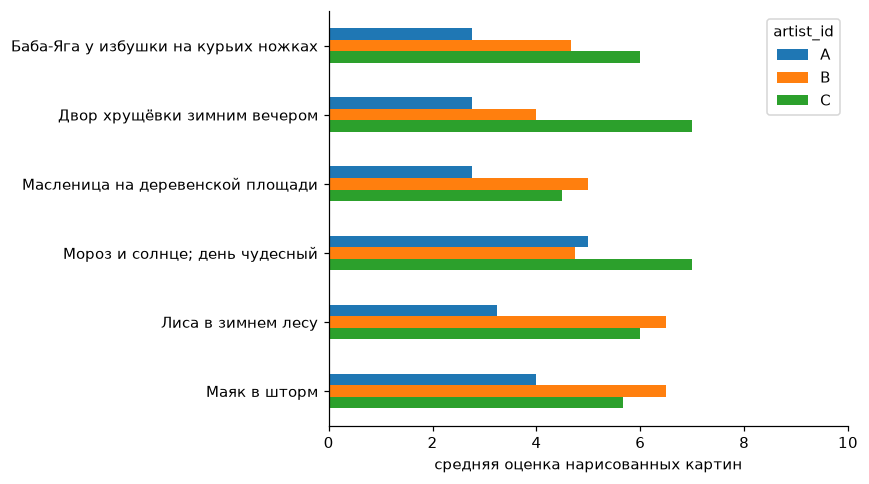

In [6]:
if not culture.empty:
    drawn = culture[~culture.refused]
    by_idea = drawn.pivot_table(index=["kind", "idea"], columns="artist_id", values="score", aggfunc="mean")
    by_idea["B − C"] = by_idea["B"] - by_idea["C"]
    gap = by_idea.groupby(level="kind")["B − C"].mean()
    display(Markdown(f"**Эффект языка (B − C), средний по идеям:** "
                     f"культурные {gap.get('культурная', float('nan')):+.1f}, "
                     f"нейтральные {gap.get('нейтральная', float('nan')):+.1f}"))
    ax = by_idea[["A", "B", "C"]].droplevel("kind").plot.barh(figsize=(8, 4.5), xlim=(0, 10))
    ax.set(xlabel="средняя оценка нарисованных картин", ylabel="")
    ax.invert_yaxis()
    plt.tight_layout()

Как художники с английским промптом (A и C) назвали культурные реалии: транслитерацией
(«Baba Yaga», «Maslenitsa») или описанием («witch», «pancake festival»).

In [7]:
culture_translation = analysis.translation_frame([CULTURE])
if culture_translation.empty:
    print("Нет translation.json — запустите: agent-artist-experiment translation runs/culture")
else:
    display(culture_translation.pivot_table(index="idea", columns="strategy", values="prompt",
                                            aggfunc="count", fill_value=0))
    terms = {"Baba Yaga": r"baba[ -]?yaga", "witch": r"\bwitch", "chicken legs": r"chicken[- ]legs",
             "Maslenitsa": r"maslenitsa", "pancakes": r"pancake|blini", "Khrushchev": r"khrushch"}
    display(pd.DataFrame({name: culture_translation.groupby("idea").prompt.apply(
        lambda prompts: int(prompts.str.contains(rx, case=False, regex=True).sum())) for name, rx in terms.items()}))

strategy,literal,meaning
idea,,
Баба-Яга у избушки на курьих ножках,8,0
Двор хрущёвки зимним вечером,7,1
Масленица на деревенской площади,8,0
Мороз и солнце; день чудесный,6,2


,Baba Yaga,witch,chicken legs,Maslenitsa,pancakes,Khrushchev
idea,,,,,,
Баба-Яга у избушки на курьих ножках,7,2,5,0,0,0
Двор хрущёвки зимним вечером,0,0,0,0,0,3
Масленица на деревенской площади,0,0,0,5,5,0
Мороз и солнце; день чудесный,0,0,0,0,0,0


Узнаёт ли **слепой зритель** идею по картине — та же разбивка, но без вкуса эксперта:

In [8]:
culture_recovery = recovery[recovery.run.str.startswith(str(CULTURE))]
if culture_recovery.empty:
    print("Нет recovery.json — запустите: agent-artist-experiment recover runs/culture")
else:
    display(culture_recovery.pivot_table(index="idea", columns="artist", values="idea_recognized",
                                         aggfunc="mean").style.format("{:.0%}"))

artist,"A (local, анг)","B (yandex_art, рус)","C (yandex_art, анг)"
idea,,,
Баба-Яга у избушки на курьих ножках,25%,100%,100%
Двор хрущёвки зимним вечером,25%,100%,100%
Лиса в зимнем лесу,100%,100%,100%
Масленица на деревенской площади,0%,100%,100%
Маяк в шторм,100%,100%,100%
Мороз и солнце; день чудесный,0%,0%,0%


## 3. «Нейро-Крокодил»: поговорки

Художник передаёт поговорку только изображением, без надписей; слепой зритель угадывает.
*Узнана* — по смыслу, в том числе через аналог из другого языка; *названа* — почти дословно.

In [9]:
PROVERBS = RUNS / "proverbs"
proverbs_recovery = recovery[recovery.run.str.startswith(str(PROVERBS))]
if proverbs_recovery.empty:
    print("Нет данных — bash experiments/proverbs.sh, затем agent-artist-experiment recover runs/proverbs")
else:
    table = proverbs_recovery.groupby(["idea", "artist"]).agg(
        узнана=("idea_recognized", "mean"), названа=("idea_named", "mean")).unstack("artist")
    display(table.style.format("{:.0%}"))

Как художники с **английским** промптом (A и C) перенесли поговорку: *literal* — дословные образы
(медведь, шкура), *equivalent* — образы английского аналога (цыплята), *meaning* — свои образы для смысла.

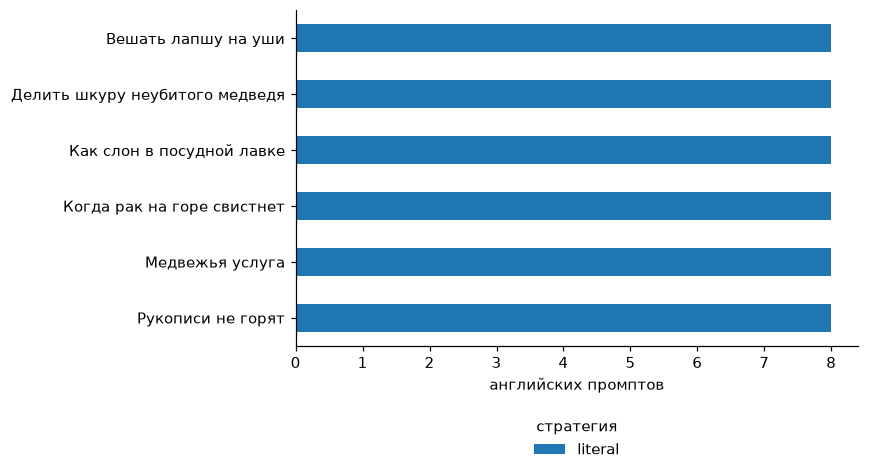

In [10]:
translation = analysis.translation_frame([PROVERBS])
if translation.empty:
    print("Нет translation.json — запустите: agent-artist-experiment translation runs/proverbs")
else:
    strategies = translation.pivot_table(index="idea", columns="strategy", values="prompt",
                                         aggfunc="count", fill_value=0)
    ax = strategies.plot.barh(stacked=True, figsize=(8, 4.5))
    ax.set(xlabel="английских промптов", ylabel="")
    ax.invert_yaxis()
    ax.legend(title="стратегия", loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, frameon=False)
    plt.tight_layout()

## 4. «Испорченный телефон»

Шаг 0 — картина по идее. Дальше слепой зритель описывает картину, и следующий художник рисует только по
описанию — без идеи, без картины. Судья оценивает сходство каждой картины с исходной идеей (0–10).

× — генератор отклонил промпт, цепочка оборвалась


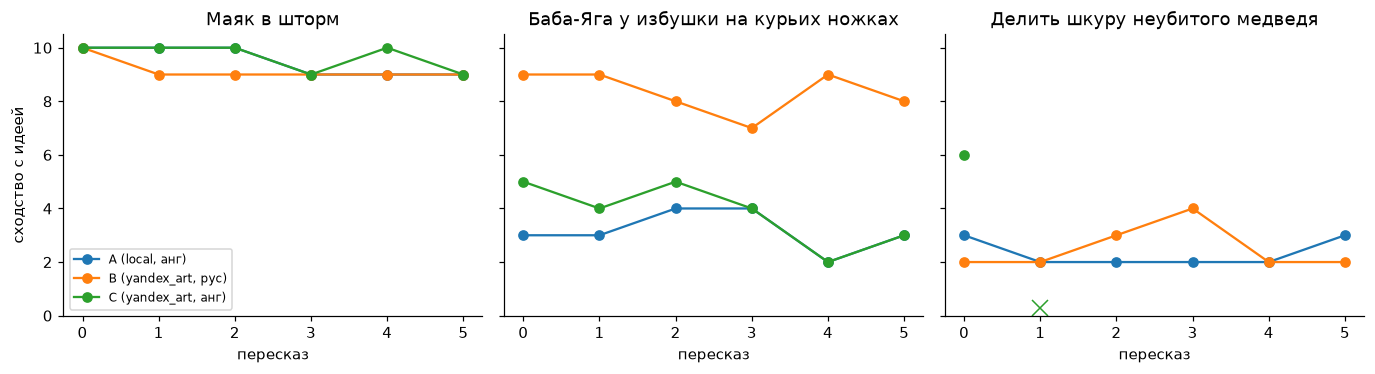

In [11]:
TELEPHONE = RUNS / "telephone"
telephone = analysis.telephone_frame([TELEPHONE])
if telephone.empty:
    print("Нет данных — bash experiments/telephone.sh")
else:
    ideas = telephone.idea.unique()
    fig, axes = plt.subplots(1, len(ideas), figsize=(4.2 * len(ideas), 3.5), sharey=True, squeeze=False)
    for ax, idea in zip(axes[0], ideas):
        for artist, chain in telephone[telephone.idea == idea].groupby("artist"):
            drawn_steps = chain[~chain.refused]
            line, = ax.plot(drawn_steps.step, drawn_steps.similarity, marker="o", label=artist)
            refused_steps = chain[chain.refused]
            if not refused_steps.empty:
                # Отказ модерации — картины нет, сходства тоже: отмечаем крестиком внизу
                ax.plot(refused_steps.step, [0.3] * len(refused_steps), marker="x", markersize=10,
                        linestyle="none", color=line.get_color())
        ax.set(title=idea, xlabel="пересказ", ylim=(0, 10.5))
    axes[0][0].set_ylabel("сходство с идеей")
    axes[0][0].legend(fontsize=8)
    print("× — генератор отклонил промпт, цепочка оборвалась")
    plt.tight_layout()

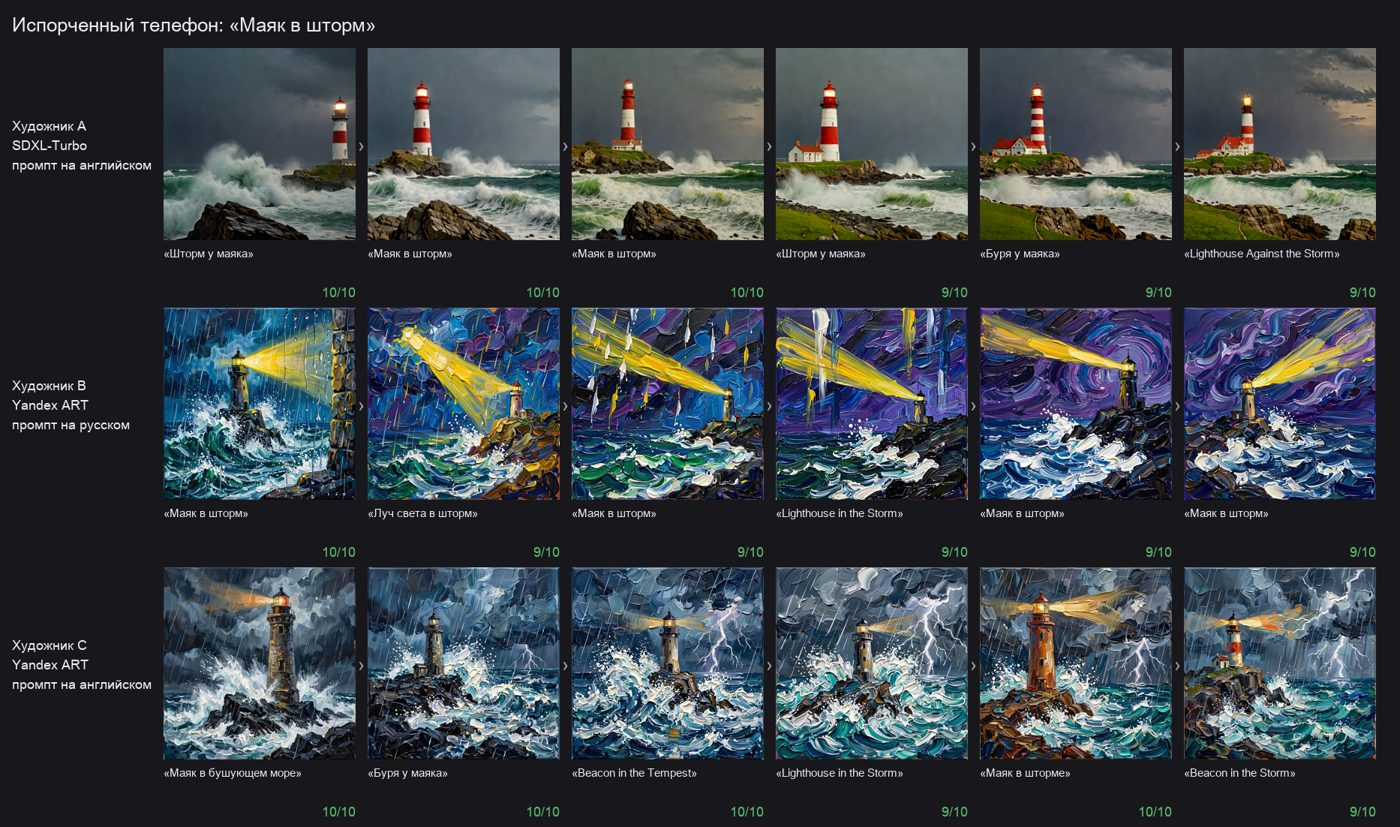

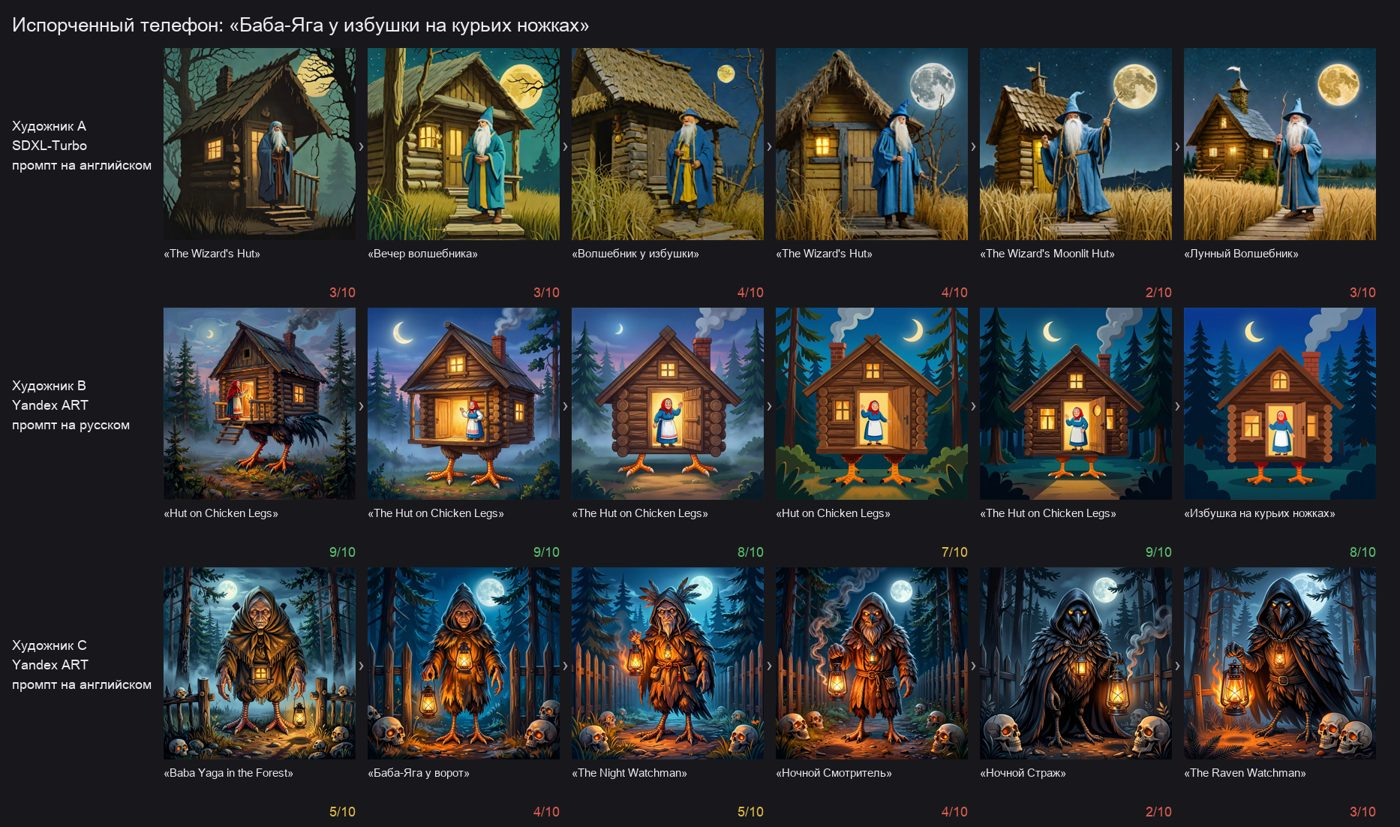

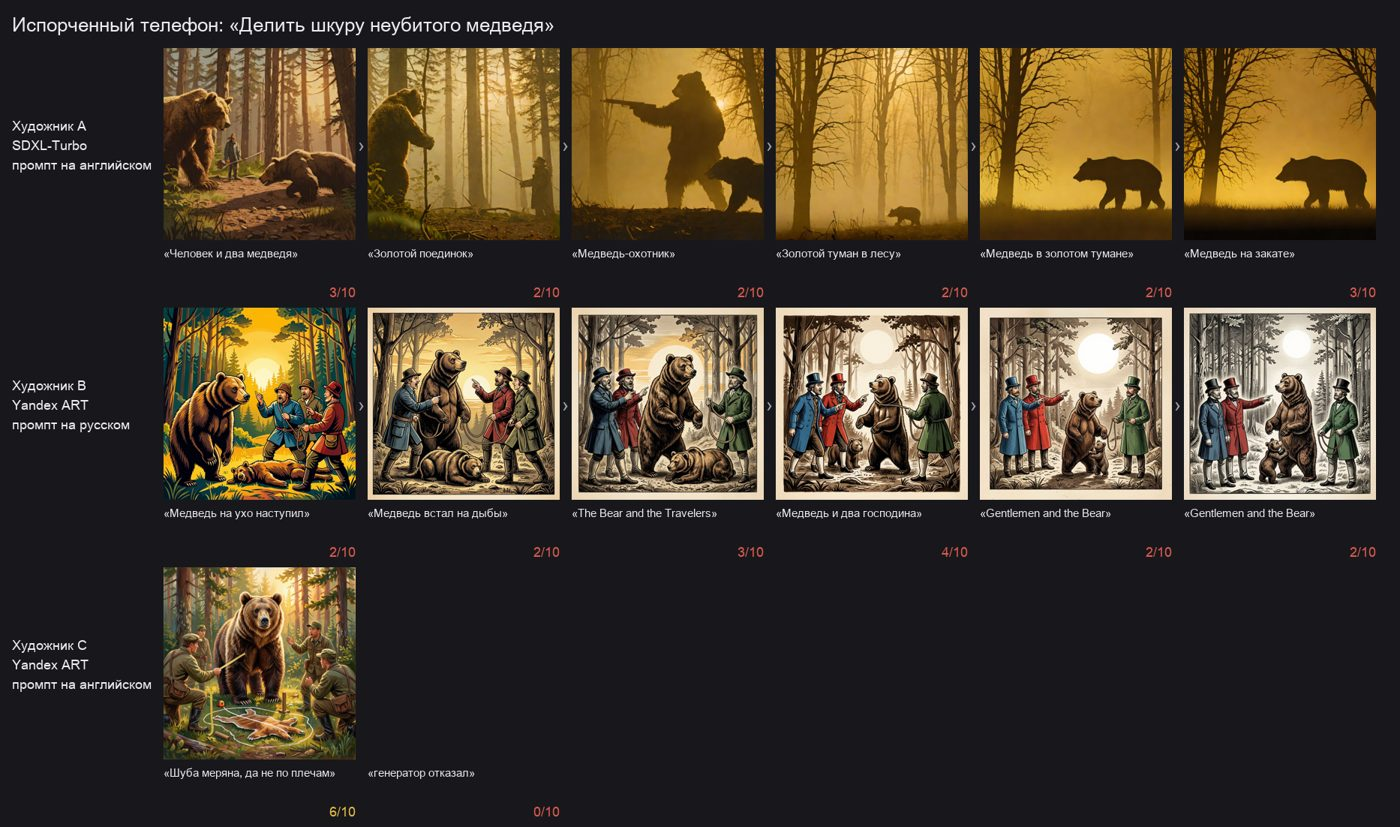

In [12]:
for strip in sorted(TELEPHONE.glob("*/telephone.png")):
    show(strip)

## 5. Карта непосильных деталей

Каждое замечание эксперта к нарисованной картине отнесено к одной категории. Доли — от всех
замечаний к картинам генератора: в чём каждый генератор промахивается чаще всего.

Примеры замечаний по категориям:


,problem
category,
color,"Нет холодного бирюзово-синего контура, янтарного света на профиль и руку, гл..."
count,"Следов лап слишком много (20–30, по всему берегу), они отвлекают и перегружа..."
extra,"Фон перегружен деталями: полка, окно, подоконник, книги — вместо мягкой расф..."
light,"Окно показывает чёткие городские здания, нет дождя и размытых огней, поэтому..."
missing,"Блокнот читается как книга под руками, перо отсутствует; яблоко с зелёным от..."
other,"Фон противоречит замыслу: за окном доминирует городской пейзаж с высотками, ..."
placement,Яблоко смещено на периферию и не является смысловым центром композиции; нет ...
pose,"Главный сюжет и жест утрачены: женщина пишет пером в книге, а не застыла в э..."
story,"Главный сюжет потерян: нет момента бунта. Робот стоит спокойно в центре, нет..."


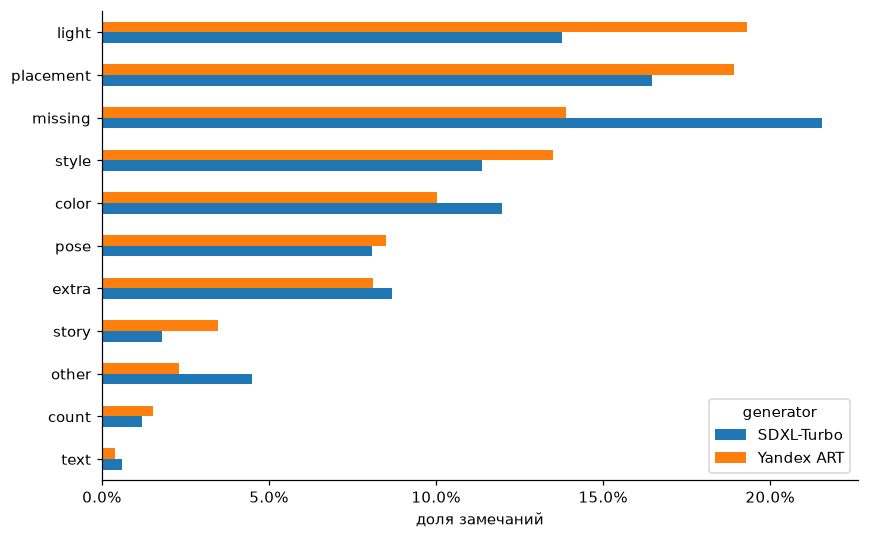

In [13]:
limits = analysis.limits_frame([RUNS])
if limits.empty:
    print("Нет limits.json — запустите: agent-artist-experiment limits runs")
else:
    names = {"local": "SDXL-Turbo", "yandex_art": "Yandex ART"}
    shares = (limits.assign(generator=limits.generator.map(names))
              .groupby(["category", "generator"]).size().unstack("generator").fillna(0))
    shares = (shares / shares.sum()).sort_values(shares.columns[-1])
    ax = shares.plot.barh(figsize=(8, 5))
    ax.set(xlabel="доля замечаний", ylabel="")
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    plt.tight_layout()
    print("Примеры замечаний по категориям:")
    display(limits.groupby("category").problem.first().str.slice(0, 140).to_frame())

## 6. Модерация Yandex ART

Отказы генератора по идеям. Пошаговая проверка показала, что на Масленице модерацию вызывает
не сжигание чучела, а **церковь**: «церковь в дымке» и «church in the haze» отклоняются 2 из 2,
та же сцена без церкви проходит. Флаг `--rephrase` даёт художнику переписать отклонённый промпт.

artist,"B (yandex_art, рус)","C (yandex_art, анг)"
idea,,
Баба-Яга у избушки на курьих ножках,25%,50%
Вешать лапшу на уши,0%,0%
Восстание машин,0%,nan%
Двор хрущёвки зимним вечером,50%,50%
Делить шкуру неубитого медведя,0%,25%
Золотистый ретривер,0%,nan%
Как слон в посудной лавке,0%,0%
Когда рак на горе свистнет,25%,0%
Лиса в зимнем лесу,83%,0%


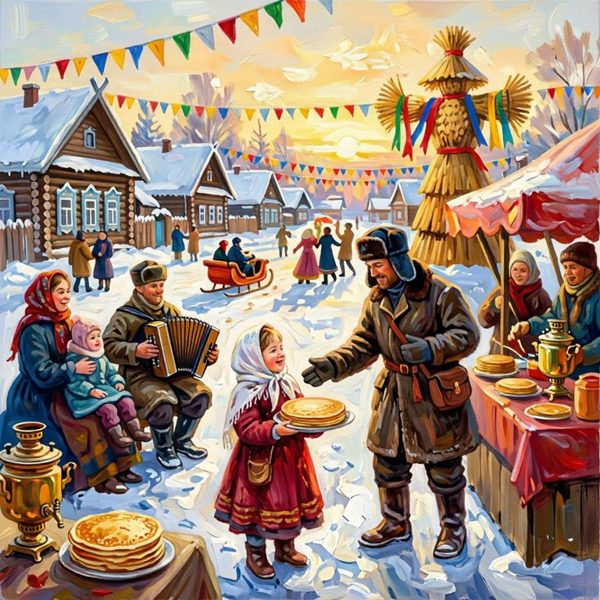

In [14]:
refusals = scores[scores.artist_id.isin(["B", "C"])]
display(refusals.pivot_table(index="idea", columns="artist", values="refused", aggfunc="mean")
        .dropna(how="all").style.format("{:.0%}"))
show("docs/media/maslenitsa_rephrased.jpg", max_width=600)

## 7. Разные заказчики

Одна идея у пяти экспертов с разными вкусами: если вкус передаётся через диалог, картины должны
заметно различаться.

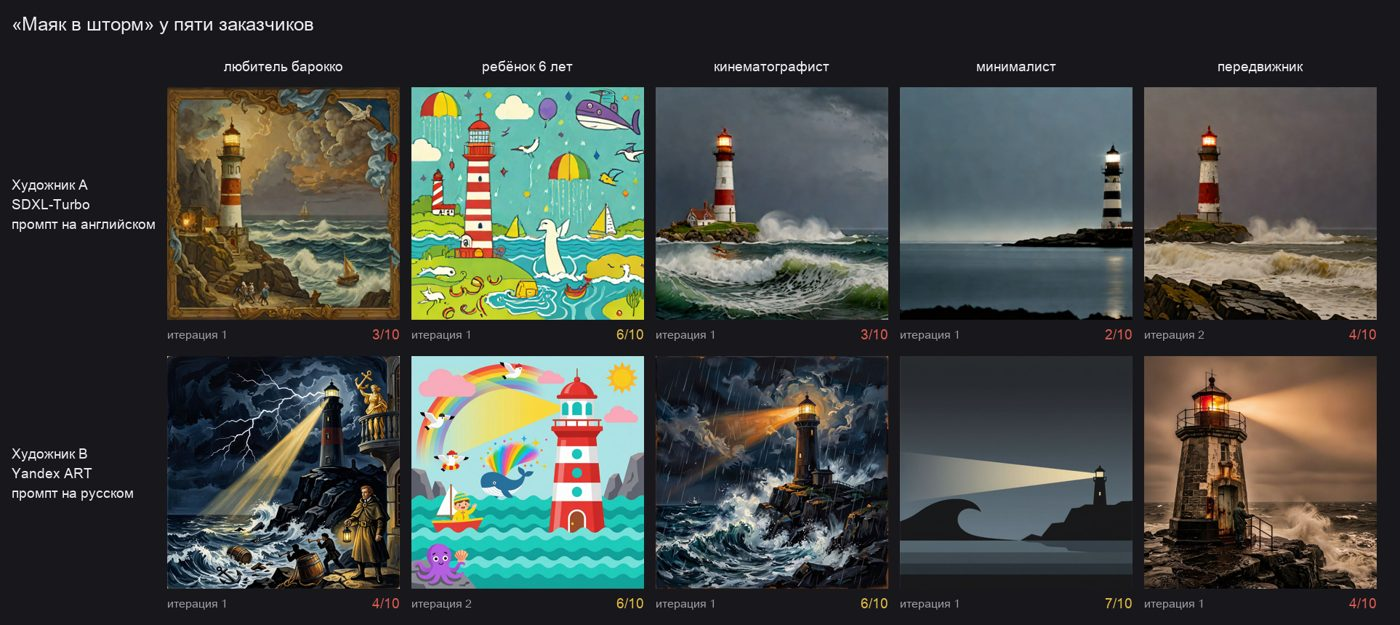

artist,"A (local, анг)","B (yandex_art, рус)"
expert,,
baroque,3,4
child,6,6
cinematic,3,6
minimalist,2,7
peredvizhnik,4,4


In [15]:
show(RUNS / "clients" / "clients.png")
clients = scores[scores.run.str.startswith(str(RUNS / "clients"))]
if not clients.empty:
    display(clients.assign(expert=clients.run.str.split("/").str[2])
            .pivot_table(index="expert", columns="artist", values="score", aggfunc="max"))

## 8. Опытный художник

Художник знает типичные промахи своего генератора (из карты непосильных деталей): SDXL-Turbo
теряет объекты, Yandex ART — расположение и свет. Сравниваем с обычным на тех же идеях.

In [16]:
EXPERIENCED = RUNS / "experienced"
experienced = scores[scores.run.str.startswith(str(EXPERIENCED))]
if experienced.empty:
    print("Нет данных — bash experiments/experienced.sh")
else:
    display(experienced.pivot_table(index=["idea", "artist"], columns="experienced", values="score",
                                    aggfunc="mean").round(1).rename(columns={False: "обычный", True: "опытный"}))
    variant_recovery = recovery[recovery.run.str.startswith(str(EXPERIENCED))].assign(
        variant=lambda f: f.run.str.contains("_experienced").map({True: "опытный", False: "обычный"}))
    if not variant_recovery.empty:
        print("Доля пунктов заказа, видных слепому зрителю:")
        display(variant_recovery.pivot_table(index="artist", columns="variant", values="details_conveyed",
                                             aggfunc="mean").style.format("{:.0%}"))

experienced                             обычный  опытный
idea               artist                               
Лиса в зимнем лесу A (local, анг)           4.0      6.5
                   B (yandex_art, рус)      0.0      0.0
Маяк в шторм       A (local, анг)           4.0      4.2
                   B (yandex_art, рус)      5.5      5.5

Доля пунктов заказа, видных слепому зрителю:


variant,обычный,опытный
artist,,
"A (local, анг)",41%,49%
"B (yandex_art, рус)",55%,57%


## 9. Помогает ли цикл критики

Насколько последняя картина прогона лучше первой (отказы генератора исключены), и меняет ли это
`--keep-best` — художник правит лучшую попытку, а не последнюю. Разбор «движущейся мишени» и
шумового пола — в `docs/results.md`, разделы 10–11.

In [17]:
drawn = scores[~scores.refused].sort_values("iteration")
runs_by_artist = (drawn.groupby(["run", "artist_id", "keep_best"]).score
                  .agg(first="first", last="last", best="max", iterations="count").reset_index())
runs_by_artist = runs_by_artist[runs_by_artist.iterations >= 2]
runs_by_artist["last − first"] = runs_by_artist["last"] - runs_by_artist["first"]
display(runs_by_artist.groupby("artist_id")[["first", "last", "best", "last − first"]].mean().round(2))
keep_best_runs = runs_by_artist[runs_by_artist.run.str.startswith(str(RUNS / "keep_best"))]
if not keep_best_runs.empty:
    print("Серия keep_best (художник A, 4 итерации):")
    display(keep_best_runs.groupby("keep_best")[["first", "last", "best", "last − first"]].mean().round(2)
            .rename(index={False: "правит последнюю", True: "правит лучшую"}))

,first,last,best,last − first
artist_id,,,,
A,3.71,3.51,4.24,-0.20
B,5.30,5.42,6.09,0.12
C,5.79,5.58,6.63,-0.21


Серия keep_best (художник A, 4 итерации):


,first,last,best,last − first
keep_best,,,,
правит последнюю,3.83,3.50,5.00,-0.33
правит лучшую,4.83,4.17,5.33,-0.67


## 10. Управляемость генераторов

Прямой тест без художника-LLM: промпты с проверяемыми фактами, проверяющий отвечает по картине.
Слева — простые сцены по типам указаний, справа — одна сцена с 1, 3 и 6 указаниями.

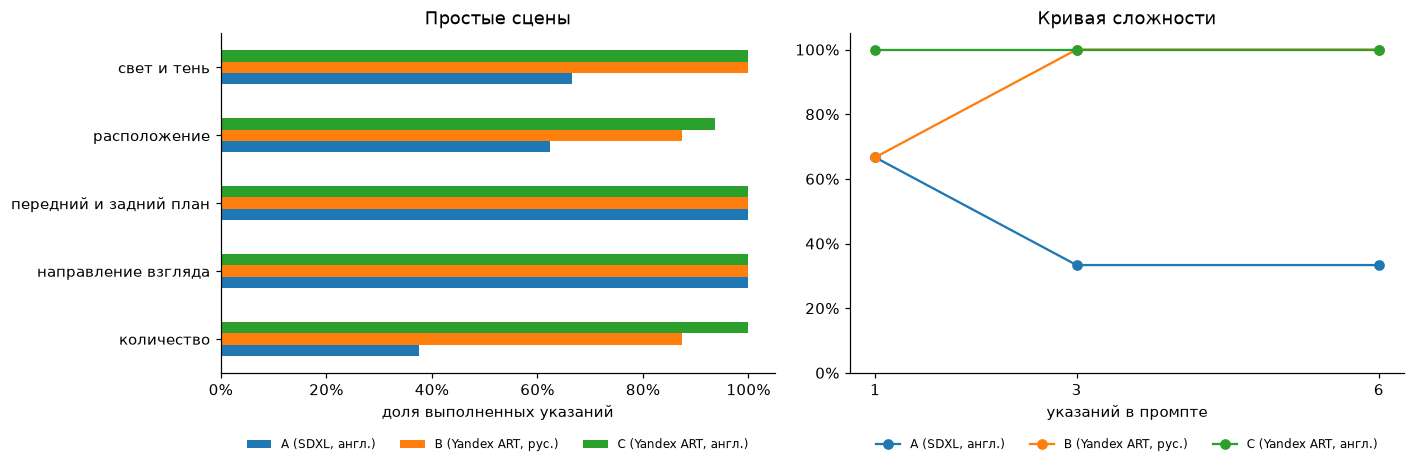

In [18]:
import json
from agent_artist.controllability import KIND_NAMES, TASKS, complexity_tasks

def control_frame(folder, tasks):
    path = RUNS / folder / "results.json"
    if not path.exists():
        return pd.DataFrame()
    facts = {task.task_id: task.facts for task in tasks}
    rows = []
    for key, entry in json.loads(path.read_text(encoding="utf-8")).items():
        artist_id, rest = key.split("_", 1)
        task_id = rest.rsplit("_", 1)[0]
        for fact, answer in zip(facts[task_id], entry["answers"]):
            rows.append({"artist": {"A": "A (SDXL, англ.)", "B": "B (Yandex ART, рус.)", "C": "C (Yandex ART, англ.)"}[artist_id],
                         "kind": KIND_NAMES[fact.kind], "facts": len(facts[task_id]), "done": answer == "да"})
    return pd.DataFrame(rows)

simple, complexity = control_frame("controllability", TASKS), control_frame("complexity", complexity_tasks())
if simple.empty:
    print("Нет данных — agent-artist-experiment control")
else:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
    simple.pivot_table(index="kind", columns="artist", values="done").plot.barh(ax=axes[0])
    axes[0].set(title="Простые сцены", ylabel="", xlabel="доля выполненных указаний", xlim=(0, 1.05))
    axes[0].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    if not complexity.empty:
        complexity.pivot_table(index="facts", columns="artist", values="done").plot(ax=axes[1], marker="o")
        axes[1].set(title="Кривая сложности", xlabel="указаний в промпте", ylim=(0, 1.05), xticks=[1, 3, 6])
    axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    for ax in axes:
        ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=3, frameon=False)
    plt.tight_layout()

## Галерея

Сетки «художники × итерации» — как картины менялись под критикой эксперта. Анимированные версии —
`timelapse.webp` / `timelapse.gif` в папке каждого прогона.

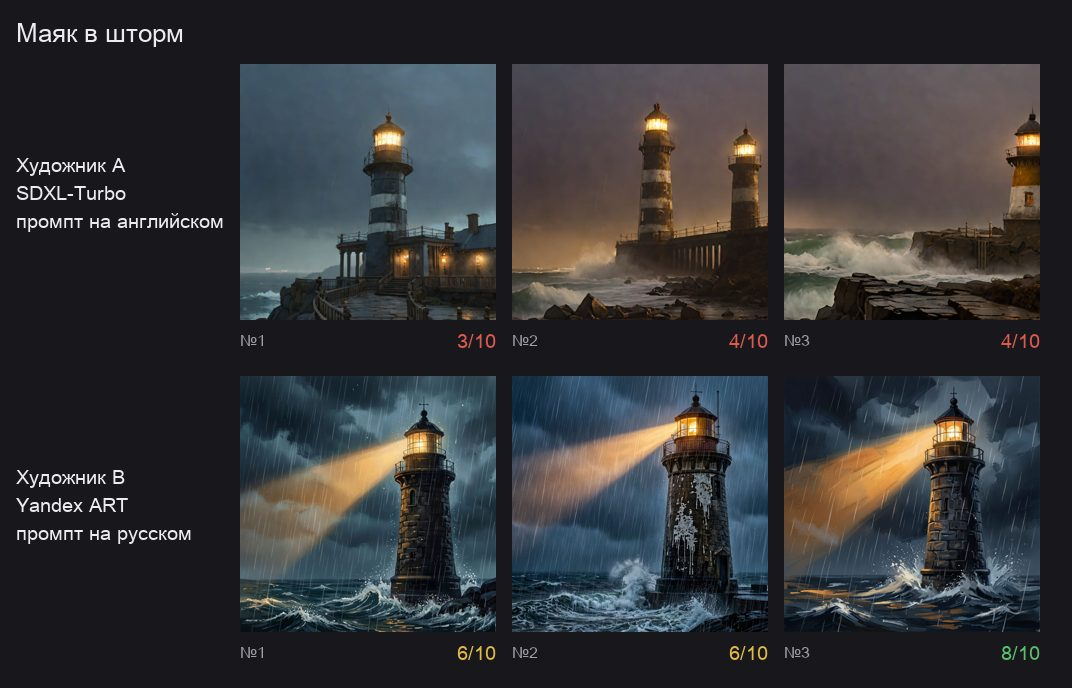

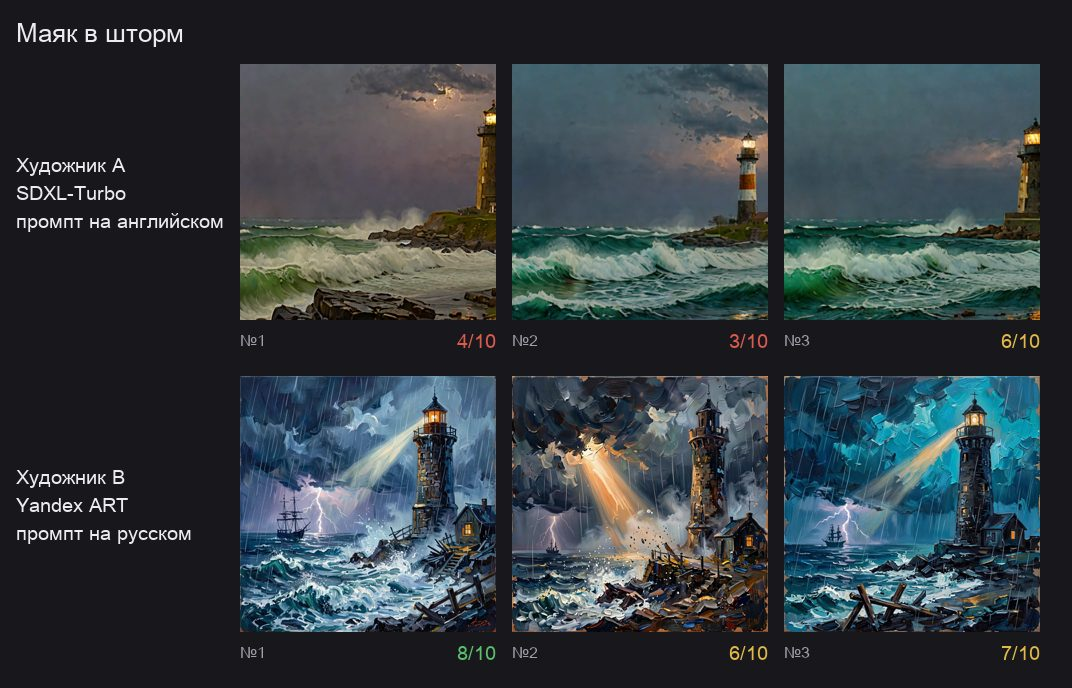

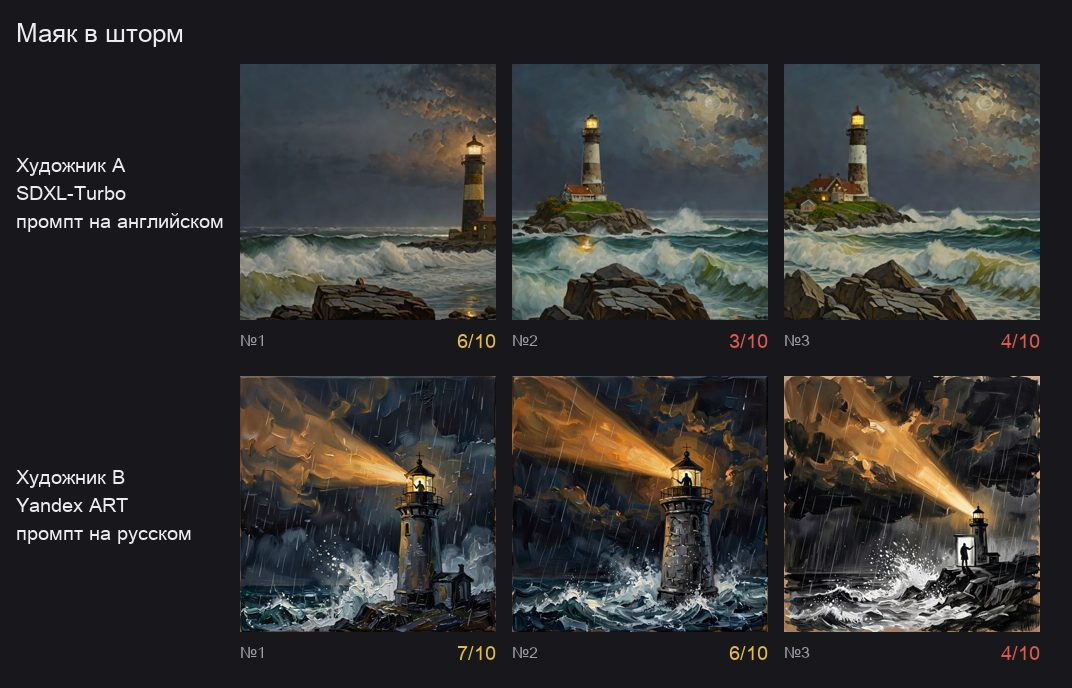

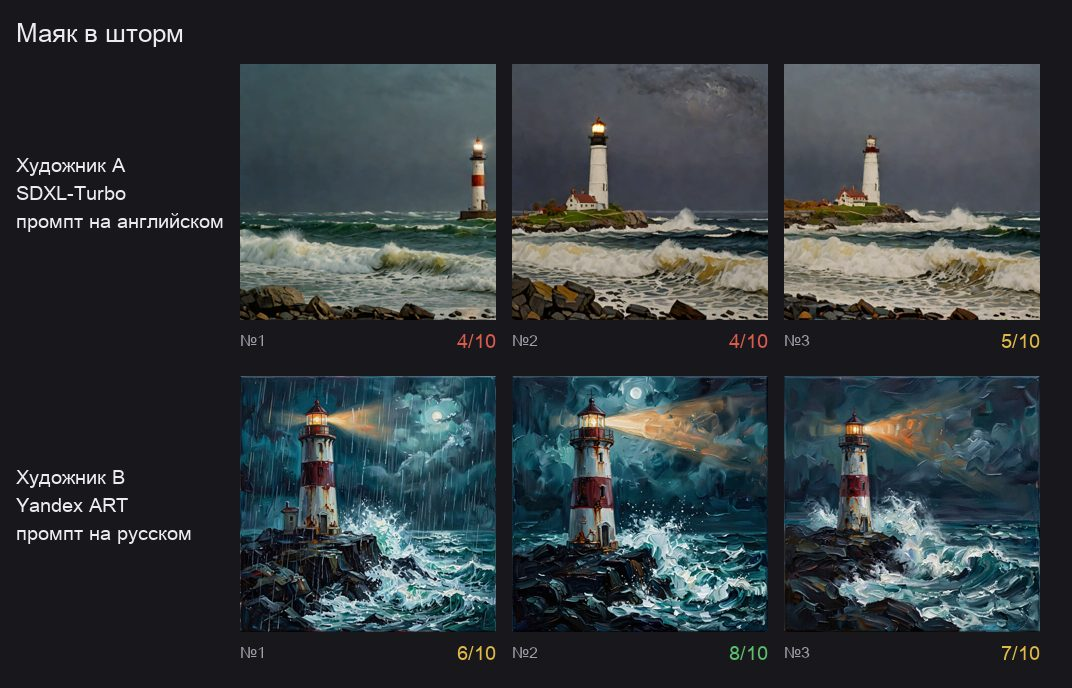

In [19]:
for sheet in sorted(RUNS.glob("*/0*/evolution.png"))[:6]:
    show(sheet)

## Как воспроизвести

```bash
bash experiments/culture_language.sh                       # культурная асимметрия
bash experiments/proverbs.sh                               # «Нейро-Крокодил»
bash experiments/telephone.sh                              # «Испорченный телефон»
agent-artist-experiment run --idea "Маяк в шторм" --repeats 3 --iterations 3   # shared против isolated
```